# Maxwell 3D inverted-pyramid light trapping — NIR absorption in a CMOS pixel surface

Reproduces the unit-cell FDTD study of **Yokogawa et al., "IR sensitivity enhancement of CMOS Image Sensor with diffractive light trapping pixels", *Sci. Rep.* 7:3832 (2017)** — [doi.org/10.1038/s41598-017-04200-y](https://doi.org/10.1038/s41598-017-04200-y) (open access). This is the paper's Fig. 2 study.

A crystalline-Si photodiode is nearly transparent in the near infrared. At λ = 850 nm the absorption depth is ~19 μm, so a 3 μm photodiode catches only ~12 %. The paper's fix is to etch a dense array of **inverted pyramids (IPA)** into the Si surface. The (111) facets at 54.7° diffract the incoming light into steep angles inside the Si, lengthening the optical path and trapping light by total internal reflection. That is wavelength-scale diffraction: no ray model captures it, and at a pyramid size of ~λ/2 effective-medium (moth-eye) approximations fail too. Full-wave 3D Maxwell in an **absorbing** medium is the honest tool.

**What you design here**

| | |
|---|---|
| **Model** | 3D time-harmonic Maxwell (full vector E field), Modified Born Series solver |
| **Structure** | ONE periodic unit cell: SiO₂ above, inverted pyramid(s) etched into the Si surface and refilled with SiO₂, Si below. The Si is made effectively infinitely deep by an absorbing bottom boundary |
| **Variables** | IPA pitch (`PITCHES`, `None` = flat reference) and wavelength (`WAVELENGTHS`, 700–1000 nm) |
| **Materials** | SiO₂ (n = 1.45) and absorbing crystalline Si with dispersion n(λ) + ik(λ) from Green 2008 |
| **Source** | normally incident plane wave, x-polarized, in the SiO₂ |
| **Metric** | absorbed fraction A in the top 3 μm of Si; FOM = A(pitch) / A(flat) |

**Validation anchors from the paper (λ = 850 nm, stated in the text)**

| surface | paper A | paper FOM | this model (default run) |
|---|---|---|---|
| flat | 12.5 % | 1.00 | 12.1 % (analytic Fresnel 12.07 %) |
| IPA pitch 400 nm | 16.5 % | 1.32 | 15.8 %, FOM 1.31 |
| IPA pitch 540 nm | 18.1 % | 1.43 (optimum) | 17.9 %, FOM 1.48 |

**Section 6 previews everything — model, materials, structure, source, monitors and boundaries — before any simulation is run.**

Size: 4 solves, the largest 2.598 Mvoxel including boundaries, 0.136 GB of memory (service estimate).

### The paper's concept (Fig. 1)
(a) The prototype back-illuminated pixel with IPA and deep-trench isolation (DTI). (b) The light-trapping idea: light refracted at the 54.7° (111) facets travels steeply and is totally reflected at the pixel sidewalls, so the optical path inside the Si lengthens. (c, d) SEM cross-section and top view of the etched inverted pyramids: exactly the shape `build_cell()` creates below.

**What this notebook takes from this figure:** only the Si surface with its inverted pyramids (the IPA layer in (a), the shape in (c, d)), on semi-infinite Si. The microlens, colour filters and DTI are not simulated here, and the sidewall reflection in (b) belongs to the full pixel. A periodic unit cell has no sidewalls, so here the gain comes from diffraction alone: the facets send light into steep angles in the Si, which lengthens its path through the 3 μm metric depth.

![Paper Fig. 1](img/paper_fig1.jpg)

*Figure reproduced from Yokogawa et al., Sci. Rep. 7:3832 (2017), [doi:10.1038/s41598-017-04200-y](https://doi.org/10.1038/s41598-017-04200-y), under a [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) licence. Unmodified.*

### What this notebook reproduces (Fig. 2)

**Paper Fig. 2 — the target of this notebook.** (a) Absorption of semi-infinite c-Si with IPA, integrated from the surface to 3 μm depth, against wavelength (x) and IPA pitch (y). (b) The same normalised by the flat surface = figure of merit (FOM). White dashed lines: the optimum pitch at each wavelength. (c) Vertical cuts of (b) at 700, 850 and 1000 nm; light dashed lines are the effective wavelengths in SiO₂ (n = 1.45), λ/n_SiO₂.

**How much of it this notebook reproduces:** the default run gives three points on the 850 nm curve in (c): flat, 400 nm and 540 nm. The EXTENSION sweep (section 2.1) gives the curves in (c) at 700, 850 and 1000 nm, sampled at 9 pitches. The maps in (a) and (b) would need a denser sweep over both wavelength and pitch.

![Paper Fig. 2](img/paper_fig2.jpg)

*Figure reproduced from Yokogawa et al., Sci. Rep. 7:3832 (2017), [doi:10.1038/s41598-017-04200-y](https://doi.org/10.1038/s41598-017-04200-y), under a [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) licence. Unmodified.*

The default run computes the three 850 nm anchors (the points on the green curve in (c) at 0, 400 and 540 nm). The EXTENSION settings in section 2.1 fill in all three curves of (c).

> **Running this notebook**
> * **Environment:** from the repository root, `pip install -e .[notebooks]` installs the client, the helpers, Jupyter and Jupytext.
> * **No account needed for sections 1–6:** they run locally (no cloud call). Run them to inspect the design.
> * **Simulations start in section 7** and run on the WaveSimPro cloud. They need an API key from [studio.rayfos.com/api-access](https://studio.rayfos.com/api-access). On the first run the client detects that no key is registered and prints how to add one.
> * **Outputs:** figures and the CSV are saved to `output/mx_ipa_light_trapping/` under the repository root (git-ignored).

## 1. Setup & imports

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt

from wavesimpro import configure, create_monitor, simulate
from wsutils import output_dir, plane_wave

NAME = "mx_ipa_light_trapping"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

## 2. Parameters
### 2.1 Sweep: wavelengths and pitches
The default is the paper's three anchor points at 850 nm (4 solves). Uncomment the EXTENSION lines for the full Fig. 2c reproduction (30 solves, the largest 7.20 Mvoxel including boundaries, 0.376 GB of memory, service estimate). `None` in `PITCHES` is the flat reference surface and must come first. Even with its 10λ absorbers (section 2.3), the 1000 nm row carries ±0.05–0.1 FOM near its Rayleigh-threshold pitches, 400 and 800 nm.

In [2]:
# DEFAULT: the paper's three text-stated anchor points at 850 nm — 4 solves; the
# console prints each result next to the paper value
# (expected: flat 12.1% [analytic 12.07%], 400 nm 15.8% FOM 1.31 [paper 1.32],
# 540 nm 17.9% FOM 1.48 [paper 1.43]).
WAVELENGTHS = [0.850]
PITCHES = [None, 0.400, 0.540]
# EXTENSION — full reproduction of the paper's Fig. 2c FOM-vs-pitch curves
# (30 solves; the 1000 nm row uses 10λ absorbers, see boundary_widths,
# and carries ±0.05-0.1 FOM near its Rayleigh-threshold pitches 400/800 nm):
# WAVELENGTHS = [0.700, 0.850, 1.000]
# PITCHES = [None, 0.200, 0.300, 0.400, 0.500, 0.540, 0.600, 0.700, 0.800]

### 2.2 Grid, SiO₂ index and flat-cell size
**Grid pitch.** The Modified Born Series (MBS) solver needs λ/4–λ/8 *in the medium*: at λ = 850 nm in Si (n ≈ 3.65) that is ~30 nm. Here the grid is 20 nm, with no mesh refinement to follow the staircased facets.

The cells are 20×20×460 (0.18 Mvoxel without boundaries) for flat and 400 nm, and 54×54×460 (1.3 Mvoxel without boundaries) for 540 nm. Section 6.1 prints the exact sizes.

In [3]:
pixel_size = 0.020    # μm. λ/8 in Si at λ=700 nm is ~23 nm, so 20 nm covers the whole
                      # 700–1000 nm band.
n_sio2 = 1.45         # SiO2 buffer above the Si and pyramid backfill (paper value)
flat_cell = 0.400     # μm, transverse cell for the flat case (size is arbitrary under
                      # periodic BCs; matching the 400 nm case reuses its reference run)

### 2.3 z-stack and absorbing boundaries
z is the propagation/depth axis (light travels towards +z); x, y are the periodic in-plane axes. The Si continues 8 μm deep into the bottom absorber, so it behaves as if infinitely deep. The absorber thickness is set in vacuum wavelengths: 5λ, or 10λ at 1000 nm where Si is nearly transparent.

* **Why so deep, with a wide absorber:** the IPA diffracts light into grazing orders in the Si (up to ~75° off-normal), where absorbing boundaries reflect worst. Any light bounced back recrosses the 3 μm metric volume and inflates A for the IPA cases (not the flat one).
* **Why 10λ at 1000 nm:** at 700 and 850 nm the Si itself damps those orders before they reach the absorber, so 5λ is enough. At 1000 nm the absorption depth is ~156 μm, so the orders arrive undamped: a 5λ absorber leaks, and the Rayleigh-threshold pitches (≈ λ/n_Si and 2λ/n_Si) show FOMs that are wrongly high. 10λ gives converged values that match paper Fig. 2c.
* **General rule:** confirm any near-threshold point by re-running with a thicker boundary.

In [4]:
# --- z-stack (propagation axis; x, y are the periodic in-plane axes) ----------
z_src = 0.30          # plane-wave source plane, inside the SiO2 (μm)
z_si0 = 1.20          # Si surface = pyramid mouths (μm)
si_depth_integr = 3.0  # absorption integrated over the top 3 μm of Si (paper's metric)
si_depth_total = 8.0   # Si continues past the metric depth into the absorbing bottom
                       # boundary -> emulates SEMI-INFINITE Si. Generous margin + a wide
                       # absorber matter here: the IPA diffracts into GRAZING orders in
                       # the Si (up to ~75° off-normal), where absorbing boundaries
                       # reflect worst — any bounce-back recrosses the 3 μm metric
                       # volume and inflates A for the IPA cases (not the flat one).

In [5]:
def boundary_widths(wavelength):
    """Absorbing-layer thickness (μm), specified in VACUUM WAVELENGTHS so a sweep
    cannot silently fall below 4-5 λ at its red end.

    The demanding case is the BOTTOM absorber: the IPA diffracts into steep orders
    that hit it far off-normal, where any absorbing ramp partially reflects. At
    700/850 nm the Si itself damps those orders before they matter and 5λ is
    sufficient. At 1000 nm the Si is nearly transparent (absorption depth ~156 μm)
    so the orders arrive undamped; a 5λ absorber then still leaks and the
    Rayleigh-threshold pitches (≈ λ/n_Si and 2λ/n_Si) read spuriously high FOMs.
    10λ gives converged values matching the paper's Fig. 2c curve. General rule:
    confirm any near-threshold point by re-running with a thicker boundary."""
    return (10.0 if wavelength >= 0.95 else 5.0) * wavelength

In [6]:
z_end = z_si0 + si_depth_total
nz = int(round(z_end / pixel_size))
iz_si0 = int(round(z_si0 / pixel_size))
iz_3um = int(round((z_si0 + si_depth_integr) / pixel_size))
iz_e0 = (int(round(2.0 / pixel_size)), int(round(4.0 / pixel_size)))  # |E0|² slab (full-field path)

facet_deg = 54.7      # Si(111) facet angle to the (100) surface — fixed by crystallography

### 2.4 Monitors — only the regions the metric and figures need come back from the cloud
**Cloud data transfer:** the solve runs remotely. With `USE_MONITORS = True` only three regions come back instead of the full (3, nx, ny, nz) volume:
* the absorbing Si block, which the metric needs;
* one thin x-z slice, for the field figure;
* a single reference plane, for |E₀|².

Set `USE_MONITORS = False` to get the full field back instead, which is useful as a cross-check of the monitor path.

In [7]:
# --- Monitors: ship only what we use back from the cloud ----------------------
# Monitor coords are domain-centred world coords: voxel i on an n-voxel axis sits
# at (i + 0.5 - n/2)*pixel_size. z-extents use ODD voxel counts so the returned
# block (2*floor(N/2)+1 voxels for a size of N*pixel_size) aligns exactly with
# the requested grid range.
USE_MONITORS = True
# Extents are DERIVED from physical lengths (not hardcoded voxel counts) so a
# pixel_size refinement run keeps the same physical monitor regions.
M_SI = 2 * (int(round((si_depth_integr + 0.6) / pixel_size)) // 2) + 1
                      # z voxels of returned Si block: surface down ~3.6 μm
                      # (covers the 3 μm metric + margin for the depth-profile plot)
IZ_SLICE0 = int(round(0.8 / pixel_size))          # x-z viz slice: 0.8 μm ..
_m = nz - 1 - IZ_SLICE0                           # .. to one voxel short of z_end
M_SLICE = _m if _m % 2 else _m - 1
IZ_REF = int(round(3.0 / pixel_size))  # single |E0|² plane (reference run, monitor path)
assert iz_si0 + M_SI <= nz and iz_3um - iz_si0 <= M_SI

### 2.5 Paper anchors

In [8]:
# Paper anchors at λ = 850 nm (absorbed fraction in the top 3 μm of Si)
PAPER_A_850 = {None: 0.125, 0.400: 0.165, 0.540: 0.181}
# Optimal IPA pitch per wavelength, as STATED IN THE PAPER'S TEXT (Fig. 2c
# discussion): "the optimal pitch of 440 nm, 540 nm and 640 nm at each wavelength".
PAPER_OPT_PITCH = {0.700: 0.440, 0.850: 0.540, 1.000: 0.640}

## 3. Materials: complex refractive index of c-Si, 0.70–1.00 μm
Tabulated from M. A. Green, *Sol. Energy Mater. Sol. Cells* 92, 1305 (2008), and interpolated for any wavelength in the band, so `WAVELENGTHS` can take any value in it: each extra wavelength adds one reference solve plus one solve per pitch.

**Absorbing Si:** a complex refractive index n + ik with k > 0 (positive imaginary part = loss).

`fresnel_flat_absorption()` is the analytic single-pass answer for the flat surface. The Si is semi-infinite, so there is no reflection from the bottom, and the simulated flat case should match it exactly.

In [9]:
# Tabulated from M. A. Green, Sol. Energy Mater. Sol. Cells 92, 1305 (2008)
# ("Self-consistent optical parameters of intrinsic silicon at 300 K").
# k = α·λ/4π from the tabulated absorption coefficient. Swap in your own
# measured (λ, n, k) table via np.interp exactly the same way.
_SI_TABLE = np.array([
    # λ (μm)   n       k
    [0.70, 3.780, 1.06e-2],
    [0.75, 3.732, 7.58e-3],
    [0.80, 3.694, 5.41e-3],
    [0.85, 3.653, 3.62e-3],
    [0.90, 3.629, 2.19e-3],
    [0.95, 3.607, 1.19e-3],
    [1.00, 3.588, 5.1e-4],
])

In [10]:
def n_si(wavelength):
    """Complex refractive index n + ik of c-Si at the given wavelength (μm).
    Positive imaginary part = absorbing."""
    n = np.interp(wavelength, _SI_TABLE[:, 0], _SI_TABLE[:, 1])
    k = np.interp(wavelength, _SI_TABLE[:, 0], _SI_TABLE[:, 2])
    return complex(n, k)

In [11]:
def fresnel_flat_absorption(wavelength):
    """Analytic check for the FLAT case: single-pass absorption in the top 3 μm
    of semi-infinite Si behind the SiO2/Si Fresnel interface. No bottom
    reflection (semi-infinite), so this is exact up to O(k²) ~ 1e-5."""
    nc = n_si(wavelength)
    r = (n_sio2 - nc) / (n_sio2 + nc)
    T = 1.0 - abs(r) ** 2
    alpha = 4 * np.pi * nc.imag / wavelength     # intensity absorption coeff (1/μm)
    return T * (1.0 - np.exp(-alpha * si_depth_integr))

## 4. Medium builder: one periodic unit cell — SiO₂ | inverted pyramid | bulk Si
`build_cell(pitch, wavelength)` returns ε = n² of one cell. Each pyramid pit has a square mouth one pitch wide (densely packed) and its apex pointing down. Its depth is (pitch/2)·tan 54.7° ≈ 0.71·pitch: the Si(111)/(100) facet angle fixes the aspect ratio, so it is not a free parameter. The pits are refilled with SiO₂, as in the paper, where the surface is planarized with passivation/oxide. The cell is given an even transverse voxel count, so the Si monitor returns exactly the full cell cross-section for the absorption integral: if pitch/pixel_size is odd, the cell holds 2×2 pyramids instead of one, which is physically identical under periodic boundaries.

In [12]:
def build_cell(pitch, wavelength):
    """Permittivity (n²) of one periodic cell, shape (nxy, nxy, nz) complex64.
    pitch=None -> flat Si surface (reference).

    The cell is forced to an EVEN transverse voxel count, so the Si monitor
    returns the full cell cross-section: if pitch/pixel_size is odd, the cell
    holds 2x2 pyramids instead of one — physically identical under periodic
    boundaries.

    Returns (permittivity, nxy, iy_slice) where iy_slice is the y-row through
    the centre (apex) of the first pyramid, for the field figure."""
    if pitch is None:
        nxy = int(round(flat_cell / pixel_size))
        n = np.full((nxy, nxy, nz), n_sio2, dtype=np.complex64)
        n[:, :, iz_si0:] = n_si(wavelength)
        return (n ** 2).astype(np.complex64), nxy, nxy // 2

    npp = int(round(pitch / pixel_size))     # voxels per pitch
    reps = 1 if npp % 2 == 0 else 2          # 2x2 pyramids if one pitch is odd
    nxy = reps * npp
    n = np.full((nxy, nxy, nz), n_sio2, dtype=np.complex64)
    n[:, :, iz_si0:] = n_si(wavelength)

    # Inverted pyramid(s): square mouth = full pitch at the surface, apex down.
    # cheb = square (Chebyshev) distance to the NEAREST pyramid centre, so the
    # same code tiles 1 or 2 pyramids per side. At depth t the etched
    # (SiO2-refilled) square has half-width w(t).
    depth = pitch / 2 * np.tan(np.deg2rad(facet_deg))
    xy = (np.arange(nxy) + 0.5) * pixel_size
    d = np.abs(xy - (np.floor(xy / pitch) + 0.5) * pitch)
    cheb = np.maximum(d[:, None], d[None, :])
    for iz in range(iz_si0, min(nz, iz_si0 + int(np.ceil(depth / pixel_size)))):
        t = (iz - iz_si0 + 0.5) * pixel_size
        w = pitch / 2 * (1 - t / depth)
        if w <= 0:
            break
        n[cheb < w, iz] = n_sio2
    return (n ** 2).astype(np.complex64), nxy, npp // 2

## 5. One solve: full-cell plane wave, periodic in x & y, absorbing in z
Source, monitors and solve helpers, defined here and **not run yet**:
* `run()` builds the source: a uniform sheet filling the cell with periodic x, y boundaries, i.e. a clean normally incident plane wave polarized along x. Absorbers sit only above and below (z).
* Normal incidence on a square-symmetric cell means one linear polarization (E_x) is enough by symmetry. For oblique incidence, average two polarizations.
* `make_monitors()` / `run_structure()` return only the Si block and one x-z slice.
* `run_reference()` is an identical run in uniform SiO₂ that calibrates the incident |E₀|², because source amplitude and field amplitude are not 1:1.

In [13]:
def run(permittivity, nxy, wavelength, monitors=None):
    # Full-cell uniform sheet source + periodic BCs = clean plane wave. The
    # half-voxel margin in the shape makes the sheet span exactly nxy voxels.
    source_values, source_position = plane_wave(
        shape=[(nxy + 0.5) * pixel_size, (nxy + 0.5) * pixel_size],
        origin="topleft",
        position=[0, 0.0, 0.0, z_src],   # polarization axis 0 = E_x (transverse)
        source_plane="xy",
        pixel_size=pixel_size,
    )
    u, iterations, residual = simulate(
        permittivity=permittivity,
        sources=[(source_values, source_position)],
        wavelength=wavelength,
        pixel_size=pixel_size,
        boundary_width=boundary_widths(wavelength),  # λ-scaled absorbers, z only
        periodic=(True, True, False),    # bottom absorber extends Si -> semi-infinite
        monitors=monitors,               # None -> full field; list -> LIST of blocks
    )
    return u, iterations, residual

In [14]:
def zcenter(iz0, m):
    """Domain-centred world z of a monitor spanning voxels iz0 .. iz0+m-1."""
    return (iz0 + (m - 1) / 2 + 0.5 - nz / 2) * pixel_size

In [15]:
def make_monitors(nxy, iy_slice):
    """Structure-run monitors: (1) the Si block the absorption metric needs,
    (2) one voxel-thin x-z slice through a pyramid apex for the field figure."""
    full = nxy * pixel_size
    si_block = create_monitor(
        name="si_block", center_x=0.0, center_y=0.0,
        center_z=zcenter(iz_si0, M_SI),
        size_x=full, size_y=full, size_z=M_SI * pixel_size)
    xz_slice = create_monitor(
        name="xz_slice", center_x=0.0,
        center_y=(iy_slice + 0.5 - nxy / 2) * pixel_size,
        center_z=zcenter(IZ_SLICE0, M_SLICE),
        size_x=full, size_y=pixel_size, size_z=M_SLICE * pixel_size)
    return [si_block, xz_slice]

In [16]:
def run_structure(permittivity, nxy, iy_slice, wavelength):
    """Solve one cell. Returns (esq_si, mag_slice, iterations, residual):
    esq_si = |E|² (pol-summed) over the Si block, shape (nxy, nxy, M_SI);
    mag_slice = |E| on the apex x-z slice, shape (nxy, M_SLICE)."""
    if USE_MONITORS:
        u, iterations, residual = run(permittivity, nxy, wavelength,
                                      monitors=make_monitors(nxy, iy_slice))
        u_si, u_slice = u[0], u[1]
    else:
        u, iterations, residual = run(permittivity, nxy, wavelength)
        u_si = u[:, :, :, iz_si0:iz_si0 + M_SI]
        u_slice = u[:, :, iy_slice:iy_slice + 1, IZ_SLICE0:IZ_SLICE0 + M_SLICE]
    esq_si = (np.abs(u_si) ** 2).sum(axis=0)
    assert esq_si.shape == (nxy, nxy, M_SI), \
        f"Si monitor returned {esq_si.shape}, expected {(nxy, nxy, M_SI)} — " \
        "the absorption sum must cover the full cell cross-section"
    mag_slice = np.sqrt((np.abs(u_slice) ** 2).sum(axis=0))[:, 0, :]
    return esq_si, mag_slice.astype(np.float32), iterations, residual

In [17]:
def run_reference(nxy, wavelength):
    """Uniform-SiO2 run calibrating the incident plane-wave |E0|² per voxel
    (source amplitude -> field amplitude is not 1:1)."""
    eps_ref = np.full((nxy, nxy, nz), n_sio2 ** 2, dtype=np.complex64)
    if USE_MONITORS:
        ref_plane = create_monitor(
            name="e0_plane", center_x=0.0, center_y=0.0,
            center_z=zcenter(IZ_REF, 1),
            size_x=nxy * pixel_size, size_y=nxy * pixel_size, size_z=pixel_size)
        u, _, _ = run(eps_ref, nxy, wavelength, monitors=[ref_plane])
        return float((np.abs(u[0]) ** 2).sum(axis=0).mean())
    u, _, _ = run(eps_ref, nxy, wavelength)
    return float((np.abs(u) ** 2).sum(axis=0)[:, :, iz_e0[0]:iz_e0[1]].mean())

## 6. Preview — what you are about to simulate
Everything in this section is computed locally from the cells above. Nothing is sent to the solver. Change parameters in section 2 and re-run to see the effect.

Preview settings (they affect only the plots below):

In [18]:
PREVIEW_WAVELENGTH = 0.850 if 0.850 in WAVELENGTHS else WAVELENGTHS[0]
PREVIEW_PITCH = 0.540 if 0.540 in PITCHES else PITCHES[-1]   # None = flat surface
PREVIEW_SPAN = 1.7    # um of periods to tile in the plots (the cell itself is periodic)

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle

MATERIAL_NAMES = ["SiO$_2$", "c-Si"]
MATERIAL_COLORS = ["#4c9be8", "#dcdcdc"]
MAT_CMAP = ListedColormap(MATERIAL_COLORS)
MAT_NORM = BoundaryNorm([-0.5, 0.5, 1.5], 2)
MAT_LEGEND = [Patch(facecolor=c, edgecolor="k", lw=0.5, label=n)
              for n, c in zip(MATERIAL_NAMES, MATERIAL_COLORS)]
Z_END = nz * pixel_size


def material_labels(eps, wavelength):
    # 0 = SiO2, 1 = c-Si (the only two materials in the cell)
    thr = 0.5 * (n_sio2 ** 2 + n_si(wavelength).real ** 2)
    return (eps.real > thr).astype(np.int8)


def tiled(eps, span=PREVIEW_SPAN):
    # Repeat the periodic cell in x and y for display; returns (array, tiles).
    t = int(np.ceil(span / (eps.shape[0] * pixel_size)))
    return np.tile(eps, (t, t, 1)), t


def pitch_label(p):
    return "flat" if p is None else f"IPA {p*1e3:.0f} nm"

### 6.1 Model summary
Physics model, grid, the cell solved for every pitch, boundary conditions and number of solves.

In [19]:
print("MODEL   3D time-harmonic Maxwell (vector E), Modified Born Series")
print(f"        ONE periodic unit cell per pitch; x, y PERIODIC, z absorbing")
print(f"GRID    pixel_size {pixel_size*1e3:.0f} nm, nz = {nz} voxels = {Z_END:.2f} um")
for wl in WAVELENGTHS:
    nc = n_si(wl)
    bw = boundary_widths(wl)
    print(f"        lambda {wl*1e3:.0f} nm: lambda_Si = {wl/nc.real*1e3:.0f} nm = "
          f"{wl/nc.real/pixel_size:.1f} voxels; z absorbers {bw:.2f} um "
          f"(= {bw/wl:.0f} lambda) above AND below")

print(f"\nCELLS   (transverse size is arbitrary under periodic BCs)")
print(f"  {'surface':<12}{'pyramids':>10}{'cell (um)':>11}{'voxels':>16}{'pyr depth':>11}"
      f"{'incl. absorbers':>17}")
for p in PITCHES:
    _, nxy_p, _ = build_cell(p, WAVELENGTHS[0])
    npp_p = None if p is None else int(round(p / pixel_size))
    n_pyr = "-" if p is None else ("1" if npp_p % 2 == 0 else "2x2")
    depth_p = 0.0 if p is None else p / 2 * np.tan(np.deg2rad(facet_deg))
    nb = int(round(max(boundary_widths(w) for w in WAVELENGTHS) / pixel_size))
    print(f"  {pitch_label(p):<12}{n_pyr:>10}{nxy_p*pixel_size:>11.2f}"
          f"{f'{nxy_p}x{nxy_p}x{nz}':>16}{depth_p:>9.3f}um"
          f"{nxy_p*nxy_p*(nz+2*nb)/1e6:>13.2f} Mvox")

n_solves = len(WAVELENGTHS) * (1 + len(PITCHES))
print(f"\nSOLVES  {len(WAVELENGTHS)} wavelength(s) x (1 SiO2 reference + {len(PITCHES)} surfaces)"
      f" = {n_solves} solves; USE_MONITORS = {USE_MONITORS}")

print("\nz-STACK (depth from the top of the domain; light enters from z = 0)")
d_max = max([0.0] + [p / 2 * np.tan(np.deg2rad(facet_deg)) for p in PITCHES if p])
stack = [("SiO2 buffer (source side)", 0.0, z_si0, "SiO2"),
         ("inverted pyramids (deepest)", z_si0, z_si0 + d_max, "SiO2 in Si"),
         ("metric volume: top 3 um of Si", z_si0, z_si0 + si_depth_integr, "c-Si"),
         ("Si run-out -> bottom absorber", z_si0 + si_depth_integr, Z_END, "c-Si")]
print(f"  {'layer':<32}{'z from':>8}{'z to':>8}{'thick':>8}   material")
for name, a, b, mat in stack:
    print(f"  {name:<32}{a:8.3f}{b:8.3f}{b-a:8.3f}   {mat}")
print(f"  source plane z_src = {z_src} um (voxel {int(z_src/pixel_size)}), in the SiO2")

print("\nVALIDATION TARGETS @ 850 nm (paper text):  " +
      ",  ".join(f"{pitch_label(p)} A = {a*100:.1f}%" for p, a in PAPER_A_850.items()))

MODEL   3D time-harmonic Maxwell (vector E), Modified Born Series
        ONE periodic unit cell per pitch; x, y PERIODIC, z absorbing
GRID    pixel_size 20 nm, nz = 460 voxels = 9.20 um
        lambda 850 nm: lambda_Si = 233 nm = 11.6 voxels; z absorbers 4.25 um (= 5 lambda) above AND below

CELLS   (transverse size is arbitrary under periodic BCs)
  surface       pyramids  cell (um)          voxels  pyr depth  incl. absorbers
  flat                 -       0.40       20x20x460    0.000um         0.35 Mvox
  IPA 400 nm           1       0.40       20x20x460    0.282um         0.35 Mvox
  IPA 540 nm         2x2       1.08       54x54x460    0.381um         2.58 Mvox

SOLVES  1 wavelength(s) x (1 SiO2 reference + 3 surfaces) = 4 solves; USE_MONITORS = True

z-STACK (depth from the top of the domain; light enters from z = 0)
  layer                             z from    z to   thick   material
  SiO2 buffer (source side)          0.000   1.200   1.200   SiO2
  inverted pyramids (deepest)

### 6.2 Materials
SiO₂ is lossless (n = 1.45). Si is dispersive and absorbing. The plots show the Green-2008 table (dots), the interpolation `n_si()` uses (line), and the wavelengths you will simulate (red). The last panel is the analytic flat-surface absorption in 3 μm of Si: the baseline the pyramids must beat.

lambda (nm)     n_Si       k_Si                  eps_Si  abs. depth  flat A (analytic)
        850    3.653   3.62e-03     13.3444 +0.02645j      18.7um            12.07%
SiO2: n = 1.45, eps = 2.1025 (lossless) — buffer above the Si and pyramid backfill


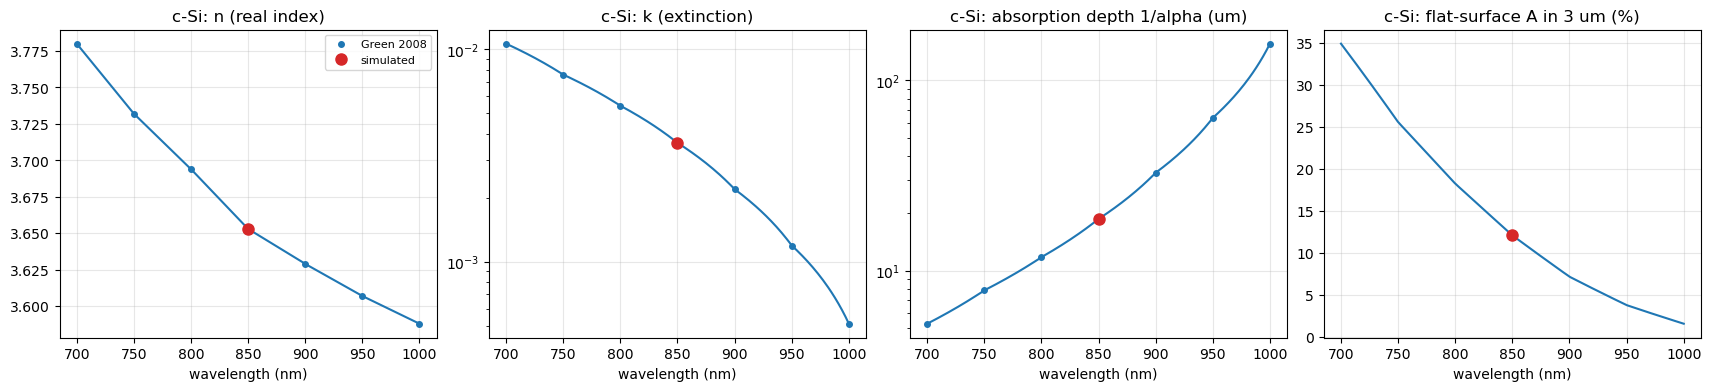

In [20]:
print(f"{'lambda (nm)':>11}{'n_Si':>9}{'k_Si':>11}{'eps_Si':>24}{'abs. depth':>12}"
      f"{'flat A (analytic)':>19}")
for wl in WAVELENGTHS:
    nc = n_si(wl)
    e = nc ** 2
    print(f"{wl*1e3:11.0f}{nc.real:9.3f}{nc.imag:11.2e}{e.real:12.4f} {e.imag:+.5f}j"
          f"{wl/(4*np.pi*nc.imag):10.1f}um{fresnel_flat_absorption(wl)*100:17.2f}%")
print(f"SiO2: n = {n_sio2}, eps = {n_sio2**2:.4f} (lossless) — buffer above the Si and pyramid backfill")

wl_fine = np.linspace(_SI_TABLE[0, 0], _SI_TABLE[-1, 0], 200)
nk = np.array([n_si(w) for w in wl_fine])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), constrained_layout=True)
panels = [("n (real index)", nk.real, _SI_TABLE[:, 1], [n_si(w).real for w in WAVELENGTHS]),
          ("k (extinction)", nk.imag, _SI_TABLE[:, 2], [n_si(w).imag for w in WAVELENGTHS]),
          ("absorption depth 1/alpha (um)", wl_fine / (4 * np.pi * nk.imag),
           _SI_TABLE[:, 0] / (4 * np.pi * _SI_TABLE[:, 2]),
           [w / (4 * np.pi * n_si(w).imag) for w in WAVELENGTHS]),
          ("flat-surface A in 3 um (%)", [fresnel_flat_absorption(w) * 100 for w in wl_fine],
           None, [fresnel_flat_absorption(w) * 100 for w in WAVELENGTHS])]
for ax, (title, curve, table, pts) in zip(axes, panels):
    ax.plot(wl_fine * 1e3, curve, color="tab:blue")
    if table is not None:
        ax.plot(_SI_TABLE[:, 0] * 1e3, table, "o", color="tab:blue", ms=4, label="Green 2008")
    ax.plot(np.array(WAVELENGTHS) * 1e3, pts, "o", color="tab:red", ms=8, label="simulated")
    ax.set(title=f"c-Si: {title}", xlabel="wavelength (nm)")
    ax.grid(alpha=0.3)
axes[1].set_yscale("log")
axes[2].set_yscale("log")
axes[0].legend(fontsize=8)
plt.show()

### 6.3 Structure — overview
Four views of `build_cell(PREVIEW_PITCH, PREVIEW_WAVELENGTH)`, **tiled** over a few periods so the array is visible (the solver sees one cell). Shading is by refractive index: dark = SiO₂ (n = 1.45), white = Si (n ≈ 3.65).
* **top-left:** top view (x-y) 0.1 μm below the Si surface — the pyramid mouths;
* **top-right / bottom-left:** side views (y-z, x-z) through a row of pyramid apexes, zoomed on the surface (the full depth is in 6.5);
* **bottom-right:** 3D cut-away.

Dashed lines show where the other cuts are taken. The red box is the one cell that is actually solved.

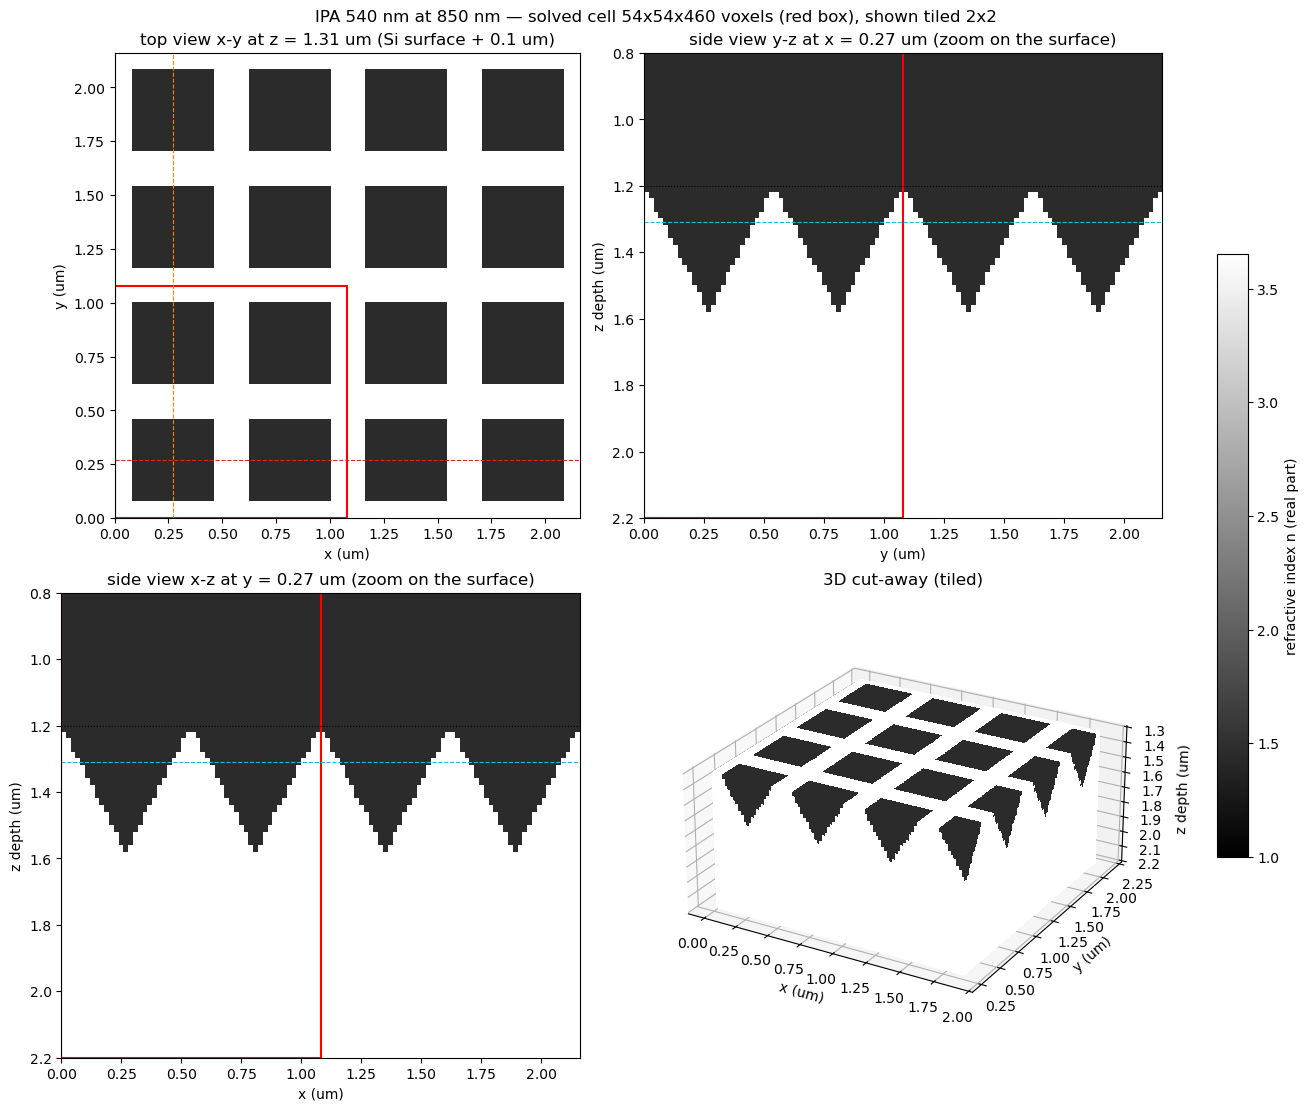

In [21]:
eps_c, nxy_c, iy_c = build_cell(PREVIEW_PITCH, PREVIEW_WAVELENGTH)
eps_t, tiles = tiled(eps_c)
nxy_t = eps_t.shape[0]
L_t = nxy_t * pixel_size
L_c = nxy_c * pixel_size
npp_c = nxy_c if PREVIEW_PITCH is None else int(round(PREVIEW_PITCH / pixel_size))
iz_top = int(round((z_si0 + 0.1) / pixel_size))          # xy cut just below the surface
z_view0, z_view1 = z_si0 - 0.4, z_si0 + 1.0               # zoom window for side views
N_KW = dict(cmap="gray", vmin=1.0, vmax=n_si(PREVIEW_WAVELENGTH).real)


def n_of(e):
    return np.sqrt(e).real


x_cut = (iy_c + 0.5) * pixel_size                         # apex row / column
z_cut = (iz_top + 0.5) * pixel_size

fig = plt.figure(figsize=(13, 11), constrained_layout=True)
ax = fig.add_subplot(2, 2, 1)
im = ax.imshow(n_of(eps_t[:, :, iz_top]).T, origin="lower", extent=[0, L_t, 0, L_t], **N_KW)
ax.axhline(x_cut, color="tab:red", ls="--", lw=0.8)
ax.axvline(x_cut, color="tab:orange", ls="--", lw=0.8)
ax.add_patch(Rectangle((0, 0), L_c, L_c, fill=False, ec="red", lw=1.5))
ax.set(title=f"top view x-y at z = {z_cut:.2f} um (Si surface + 0.1 um)",
       xlabel="x (um)", ylabel="y (um)")

for k, (arr, lab) in enumerate([(eps_t[iy_c, :, :], "y-z at x"), (eps_t[:, iy_c, :], "x-z at y")]):
    ax = fig.add_subplot(2, 2, 2 if k == 0 else 3)
    ax.imshow(n_of(arr).T, origin="upper", extent=[0, L_t, Z_END, 0], aspect="auto", **N_KW)
    ax.set_ylim(z_view1, z_view0)
    ax.axhline(z_cut, color="tab:cyan", ls="--", lw=0.8)
    ax.axhline(z_si0, color="k", ls=":", lw=0.8)
    ax.add_patch(Rectangle((0, z_view0), L_c, z_view1 - z_view0, fill=False, ec="red", lw=1.5))
    ax.set(title=f"side view {lab} = {x_cut:.2f} um (zoom on the surface)",
           xlabel=("y" if k == 0 else "x") + " (um)", ylabel="z depth (um)")

ax = fig.add_subplot(2, 2, 4, projection="3d")
xv = (np.arange(nxy_t) + 0.5) * pixel_size
zv = (np.arange(nz) + 0.5) * pixel_size
ixR = nxy_t - npp_c // 2 - 1
iz0, iz1 = iz_top, int(round(z_view1 / pixel_size))
xs, ys, zs = np.arange(0, ixR + 1), np.arange(iy_c, nxy_t), np.arange(iz0, iz1)
gray = plt.get_cmap("gray")
nrm = lambda v: gray((v - N_KW["vmin"]) / (N_KW["vmax"] - N_KW["vmin"]))


def face(X, Y, Z, vals):
    X, Y, Z = (np.broadcast_to(a, vals.shape) for a in (X, Y, Z))
    ax.plot_surface(X, Y, -Z, facecolors=nrm(vals), rstride=1, cstride=1,
                    shade=False, linewidth=0, antialiased=False)


face(xv[xs][:, None], xv[iy_c], zv[zs][None, :], n_of(eps_t[xs][:, iy_c][:, zs]))       # front
face(xv[ixR], xv[ys][:, None], zv[zs][None, :], n_of(eps_t[ixR][ys][:, zs]))            # right
face(xv[xs][:, None], xv[ys][None, :], zv[iz0], n_of(eps_t[xs][:, ys, iz0]))            # top
ax.set_box_aspect((xv[ixR], L_t - xv[iy_c], zv[iz1] - zv[iz0]))
ax.set(xlabel="x (um)", ylabel="y (um)", zlabel="z depth (um)", title="3D cut-away (tiled)")
ax.zaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{-v:.1f}"))
ax.view_init(elev=25, azim=-60)

fig.colorbar(im, ax=fig.axes[:3], shrink=0.6, label="refractive index n (real part)")
fig.suptitle(f"{pitch_label(PREVIEW_PITCH)} at {PREVIEW_WAVELENGTH*1e3:.0f} nm — solved cell "
             f"{nxy_c}x{nxy_c}x{nz} voxels (red box), shown tiled {tiles}x{tiles}", fontsize=12)
plt.show()

### 6.4 Structure — every surface in the sweep
Top row: x-z cuts through the pyramid apexes for every entry of `PITCHES`, at the same scale. The mouths are one pitch wide and the facet angle is fixed at 54.7°, so a larger pitch gives deeper pits. Bottom row: for the preview pitch, the SiO₂-filled square shrinks with depth until the apex. Compare with the SEM images in paper Fig. 1(c, d).

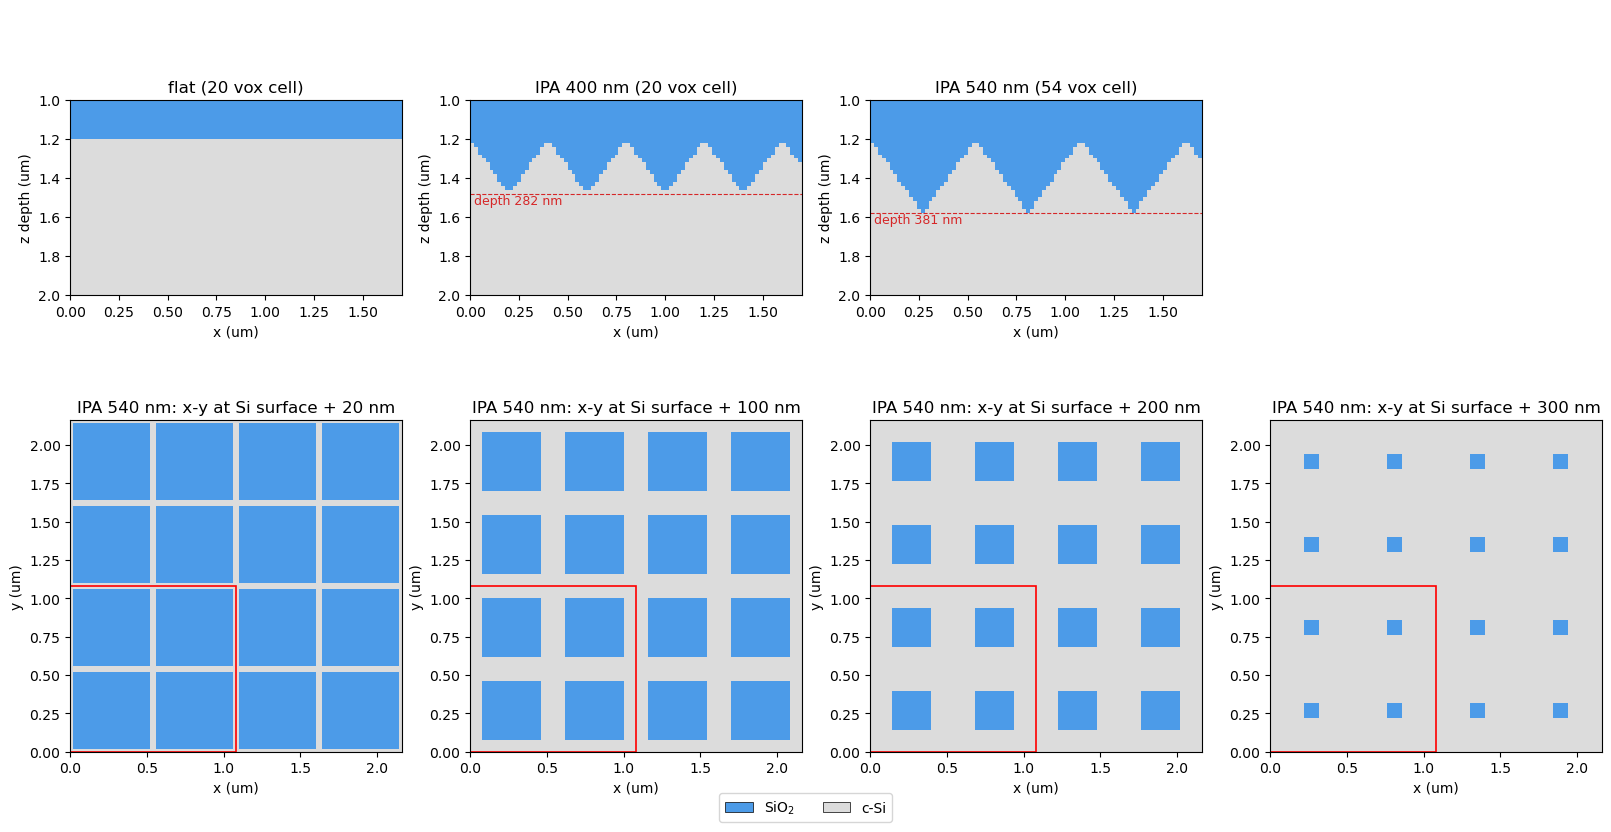

In [22]:
fig, axes = plt.subplots(2, max(len(PITCHES), 4), figsize=(4 * max(len(PITCHES), 4), 8),
                         constrained_layout=True, squeeze=False)
for ax in axes[0, len(PITCHES):]:
    ax.axis("off")
for ax, p in zip(axes[0], PITCHES):
    e, nxy_p, iy_p = build_cell(p, PREVIEW_WAVELENGTH)
    e, _ = tiled(e)
    ax.imshow(material_labels(e[:, iy_p, :], PREVIEW_WAVELENGTH).T, origin="upper",
              cmap=MAT_CMAP, norm=MAT_NORM, extent=[0, e.shape[0] * pixel_size, Z_END, 0],
              aspect="equal", interpolation="nearest")
    ax.set_xlim(0, PREVIEW_SPAN)
    ax.set_ylim(z_si0 + 0.8, z_si0 - 0.2)
    if p is not None:
        dp = p / 2 * np.tan(np.deg2rad(facet_deg))
        ax.axhline(z_si0 + dp, color="tab:red", ls="--", lw=0.8)
        ax.text(0.02, z_si0 + dp + 0.05, f"depth {dp*1e3:.0f} nm", color="tab:red", fontsize=9)
    ax.set(title=f"{pitch_label(p)} ({nxy_p} vox cell)", xlabel="x (um)", ylabel="z depth (um)")

depths = [0.02, 0.1, 0.2, 0.3] if PREVIEW_PITCH else [0.1]
for ax, dz in zip(axes[1], depths):
    iz = iz_si0 + int(round(dz / pixel_size))
    ax.imshow(material_labels(eps_t[:, :, iz], PREVIEW_WAVELENGTH).T, origin="lower",
              cmap=MAT_CMAP, norm=MAT_NORM, extent=[0, L_t, 0, L_t], interpolation="nearest")
    ax.add_patch(Rectangle((0, 0), L_c, L_c, fill=False, ec="red", lw=1.2))
    ax.set(title=f"{pitch_label(PREVIEW_PITCH)}: x-y at Si surface + {dz*1e3:.0f} nm",
           xlabel="x (um)", ylabel="y (um)")
for ax in axes[1, len(depths):]:
    ax.axis("off")
fig.legend(handles=MAT_LEGEND, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03))
plt.show()

### 6.5 Source, monitors and boundaries
* **(a)** The source: the plane wave `run()` builds, with uniform amplitude over the cell, polarized along x.
* **(b)** Structure runs: the full-depth cell with the source plane, the two monitors (the regions that come back from the cloud), the 3 μm metric depth, and the absorbing layers the solver adds above and below (hatched). x and y are periodic, so there are no side absorbers.
* **(c)** Reference run: the same source in uniform SiO₂ with a single-plane monitor, which calibrates |E₀|² once per wavelength.

source: plane wave, x-polarized, normal incidence, plane z = 0.30 um (voxel 15), 54x54 voxels = the full cell, |amplitude| = 1.00
boundaries at 850 nm: x, y periodic; z absorbing, 4.25 um above and below the 9.2 um domain


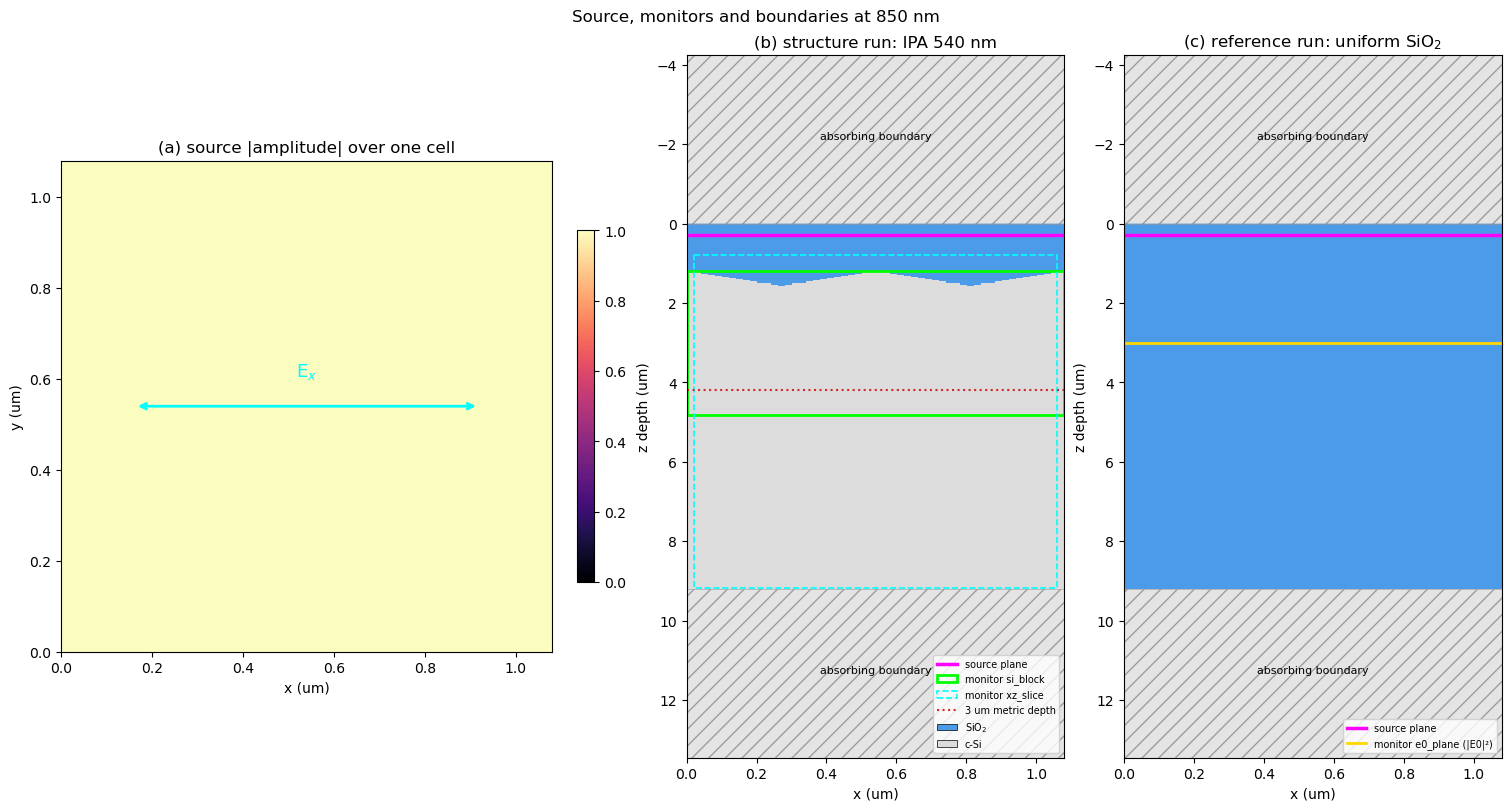

In [23]:
pw_values, pw_position = plane_wave(               # identical to the call inside run()
    shape=[(nxy_c + 0.5) * pixel_size, (nxy_c + 0.5) * pixel_size], origin="topleft",
    position=[0, 0.0, 0.0, z_src], source_plane="xy", pixel_size=pixel_size)
pw_amp = np.abs(pw_values[0, :, :, 0])
pol = "xyz"[pw_position[0]]
bw = boundary_widths(PREVIEW_WAVELENGTH)
print(f"source: plane wave, {pol}-polarized, normal incidence, plane z = "
      f"{pw_position[3]*pixel_size:.2f} um (voxel {pw_position[3]}), "
      f"{pw_amp.shape[0]}x{pw_amp.shape[1]} voxels = the full cell, |amplitude| = {pw_amp.max():.2f}")
print(f"boundaries at {PREVIEW_WAVELENGTH*1e3:.0f} nm: x, y periodic; z absorbing, {bw:.2f} um "
      f"above and below the {Z_END:.1f} um domain")

fig, axes = plt.subplots(1, 3, figsize=(15, 8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
im = ax.imshow(pw_amp.T, origin="lower", extent=[0, L_c, 0, L_c], cmap="magma", vmin=0, vmax=1)
ax.annotate("", xy=(0.85 * L_c, 0.5 * L_c), xytext=(0.15 * L_c, 0.5 * L_c),
            arrowprops=dict(arrowstyle="<->", color="cyan", lw=2))
ax.text(0.5 * L_c, 0.56 * L_c, f"E$_{pol}$", color="cyan", ha="center", fontsize=13)
ax.set(title="(a) source |amplitude| over one cell", xlabel="x (um)", ylabel="y (um)")
fig.colorbar(im, ax=ax, shrink=0.5)


def side_view(ax, lab, title):
    ax.imshow(lab.T, origin="upper", cmap=MAT_CMAP, norm=MAT_NORM,
              extent=[0, L_c, Z_END, 0], aspect="auto", interpolation="nearest")
    for z0 in (-bw, Z_END):
        ax.add_patch(Rectangle((0, z0), L_c, bw, facecolor="0.85", edgecolor="0.5",
                               hatch="//", alpha=0.7, lw=0.5))
    ax.plot([0, L_c], [z_src, z_src], color="magenta", lw=2.5, label="source plane")
    ax.set_xlim(0, L_c)
    ax.set_ylim(Z_END + bw, -bw)
    ax.set(title=title, xlabel="x (um)", ylabel="z depth (um)")
    ax.text(L_c / 2, -bw / 2, "absorbing boundary", ha="center", fontsize=8)
    ax.text(L_c / 2, Z_END + bw / 2, "absorbing boundary", ha="center", fontsize=8)


side_view(axes[1], material_labels(eps_c[:, iy_c, :], PREVIEW_WAVELENGTH),
          f"(b) structure run: {pitch_label(PREVIEW_PITCH)}")
ax = axes[1]
ax.add_patch(Rectangle((0, iz_si0 * pixel_size), L_c, M_SI * pixel_size, fill=False,
                       ec="lime", lw=2, label="monitor si_block"))
ax.add_patch(Rectangle((0.02 * L_c, IZ_SLICE0 * pixel_size), 0.96 * L_c, M_SLICE * pixel_size,
                       fill=False, ec="cyan", lw=1.2, ls="--", label="monitor xz_slice"))
ax.axhline(z_si0 + si_depth_integr, color="tab:red", ls=":", lw=1.5, label="3 um metric depth")
ax.legend(handles=ax.get_legend_handles_labels()[0] + MAT_LEGEND, fontsize=7, loc="lower right")

eps_ref_prev = np.full((nxy_c, 1, nz), n_sio2 ** 2, dtype=np.complex64)   # a slice of the reference medium
side_view(axes[2], material_labels(eps_ref_prev[:, 0, :], PREVIEW_WAVELENGTH),
          "(c) reference run: uniform SiO$_2$")
ax = axes[2]
ax.axhline((IZ_REF + 0.5) * pixel_size, color="gold", lw=2, label="monitor e0_plane (|E0|²)")
ax.legend(fontsize=7, loc="lower right")
fig.suptitle(f"Source, monitors and boundaries at {PREVIEW_WAVELENGTH*1e3:.0f} nm", fontsize=12)
plt.show()

## 7. Run the sweep
For each wavelength: one uniform-SiO₂ reference run (|E₀|²), then one solve per pitch. For each solve the notebook prints the absorbed fraction A in the top 3 μm of Si, the FOM and the paper anchor. The flat case is also checked against the analytic Fresnel answer.

**How absorption is measured:** the absorbed power density in the lossy Si is (ω ε₀ / 2)·Im(ε)·|E|². Normalising by the incident power through the cell gives the absorbed fraction

A = k₀ · Σ Im(ε)|E|² · dV / (n_SiO₂ · |E₀|² · A_cell),

summed over the top 3 μm of Si, with |E₀|² from the reference run. SiO₂ has Im(ε) = 0, so the pyramid backfill contributes nothing.

One reference run per wavelength is enough: a uniform sheet source under periodic boundaries radiates a fixed amplitude per unit area, so |E₀|² does not depend on the transverse cell size and is never re-run per pitch.

Expected (default): flat 12.1 % (analytic 12.07 %), 400 nm 15.8 % FOM 1.31, 540 nm 17.9 % FOM 1.48.

In [24]:
results = []       # dicts: wavelength, pitch, A, fom
profiles = {}      # (wavelength, pitch) -> cumulative absorption vs depth, for plots
fields = {}        # (wavelength, pitch) -> |E| x-z slice through the cell centre

for wavelength in WAVELENGTHS:
    k0 = 2 * np.pi / wavelength
    nc = n_si(wavelength)
    print(f"\nlambda = {wavelength*1e3:.0f} nm   n_Si = {nc.real:.3f} + {nc.imag:.2e}j "
          f"(absorption depth {wavelength / (4 * np.pi * nc.imag):.1f} um)")

    # ONE |E0|² calibration per wavelength: a uniform sheet source under periodic
    # BCs radiates a fixed amplitude PER UNIT AREA, so the reference cannot depend
    # on the transverse cell size — never re-run it per pitch/cell.
    e0sq = run_reference(int(round(flat_cell / pixel_size)), wavelength)
    a_flat = None

    for pitch in PITCHES:
        permittivity, nxy, iy_slice = build_cell(pitch, wavelength)

        label = "flat" if pitch is None else f"pitch {pitch*1e3:.0f} nm"
        start = time()
        esq_si, mag_slice, iters, res = run_structure(permittivity, nxy, iy_slice, wavelength)

        # Absorbed fraction: A = k0 * sum(Im(eps)|E|^2) * dV / (n_SiO2 |E0|^2 A_cell),
        # with dV/A_cell = pixel_size / (nxy*nxy). Restricted to the top 3 um of Si
        # (SiO2 has Im(eps)=0, so the pyramid backfill contributes nothing).
        eps_im = permittivity.imag[:, :, iz_si0:iz_si0 + M_SI]
        prof = (eps_im * esq_si).sum(axis=(0, 1))   # per z-slice of the Si block
        norm = k0 * pixel_size / (n_sio2 * e0sq * nxy * nxy)
        A = norm * prof[:iz_3um - iz_si0].sum()

        if pitch is None:
            a_flat = A
        fom = A / a_flat if a_flat else float("nan")
        results.append(dict(wavelength=wavelength, pitch=pitch, A=A, fom=fom))
        profiles[(wavelength, pitch)] = norm * np.cumsum(prof)
        fields[(wavelength, pitch)] = mag_slice

        anchor = PAPER_A_850.get(pitch) if abs(wavelength - 0.850) < 1e-6 else None
        anchor_txt = f"  paper {anchor*100:.1f}%" if anchor else ""
        print(f"  {label:<13} A = {A*100:5.2f}%  FOM = {fom:4.2f}{anchor_txt}   "
              f"({nxy}x{nxy}x{nz} vox, {iters} iters, res {res:.1e}, {time()-start:.1f} s)")

    print(f"  analytic Fresnel check (flat): A = {fresnel_flat_absorption(wavelength)*100:.2f}% "
          f"vs simulated {a_flat*100:.2f}%")


lambda = 850 nm   n_Si = 3.653 + 3.62e-03j (absorption depth 18.7 um)

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : b7b7fba3-d313-4ee0-89fc-f3902a869dcc
  Version   : 9d05eff0-91b7-45f2-8a63-9a565ced43ae
  Command   : 66a91f88-0eb0-4472-9798-4219518f17ed
  Mode      : Maxwell (vectorial)
  Domain    : 20x20x460 voxels  lambda=0.85 um  dx=0.020 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 57c28f85-e010-41c7-8dfa-eaa9f6e0306c
  Version   : 719e0f5f-e88f-42ab-bcb8-fd4278754a20
  Command   : 998f1486-b010-4caa-a877-f91ec5b09950
  Mode      : Maxwell (vectorial)
  Domain    : 20x20x460 voxels  lambda=0.85 um  dx=0.020 um
  Engine

## 8. Results
### Figure 1 — |E| cross-sections (flat vs best IPA) + cumulative absorption vs depth
A steeper cumulative curve means more absorption per unit depth: the lengthened path from light trapping.

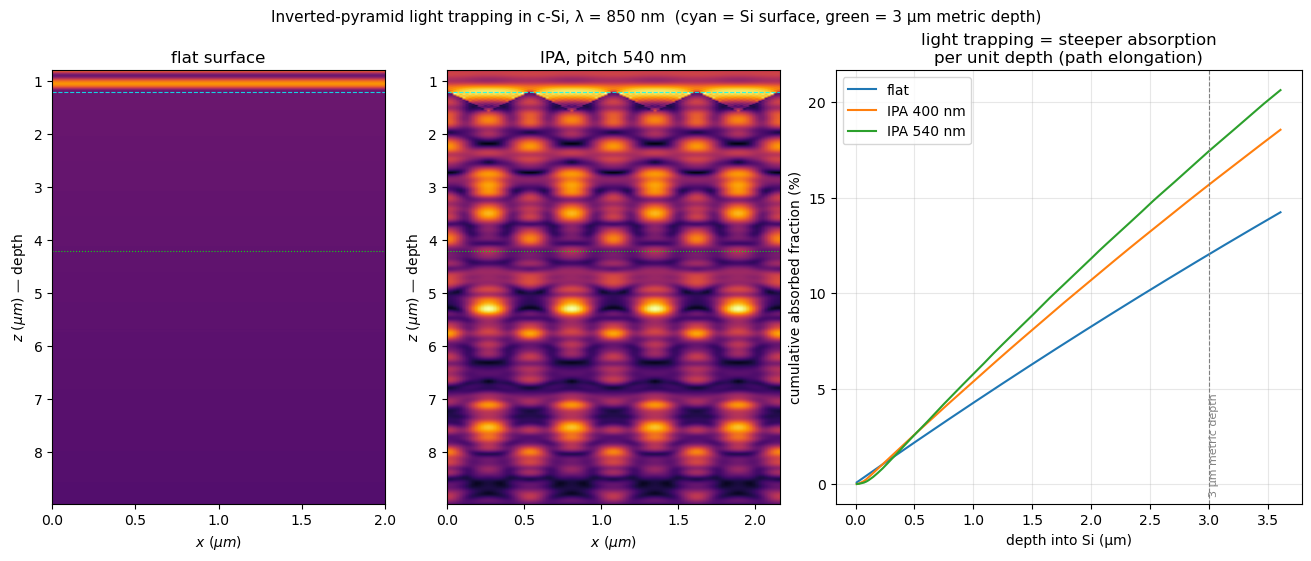

In [25]:
wl0 = 0.850 if 0.850 in WAVELENGTHS else WAVELENGTHS[0]   # headline wavelength
show_pitches = [None, 0.540 if 0.540 in PITCHES else PITCHES[-1]]
profile_pitches = [p for p in PITCHES if p in (None, 0.400, 0.540, 0.800)]
vmax = max(fields[(wl0, p)].max() for p in show_pitches)
span_x = 1.7  # μm of tiled periods to display (the periodic field tiles exactly)

fig, axes = plt.subplots(1, 3, figsize=(13, 5.5), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 1, 1.4]})
z_slice0, z_slice1 = IZ_SLICE0 * pixel_size, (IZ_SLICE0 + M_SLICE) * pixel_size
for ax, pitch in zip(axes[:2], show_pitches):
    mag = fields[(wl0, pitch)]                       # (nxy, M_SLICE) slice at y = centre
    cell = mag.shape[0] * pixel_size
    tiles = int(np.ceil(span_x / cell))
    mag = np.tile(mag, (tiles, 1))
    extent = [0, tiles * cell, z_slice1, z_slice0]   # depth increases downward
    ax.imshow(mag.T, cmap="inferno", extent=extent, vmin=0, vmax=vmax, aspect="auto")
    ax.axhline(z_si0, color="cyan", lw=0.8, ls="--", alpha=0.8)
    ax.axhline(z_si0 + si_depth_integr, color="lime", lw=0.8, ls=":", alpha=0.8)
    ax.set_ylim(z_slice1 - 0.2, z_slice0)            # crop source run-up clutter
    ax.set_xlabel(r"$x~(\mu m)$")
    ax.set_ylabel(r"$z~(\mu m)$ — depth")
    ax.set_title("flat surface" if pitch is None
                 else f"IPA, pitch {pitch*1e3:.0f} nm")

ax = axes[2]
z_si = (np.arange(M_SI) + 0.5) * pixel_size
for pitch in profile_pitches:
    lab = "flat" if pitch is None else f"IPA {pitch*1e3:.0f} nm"
    ax.plot(z_si, profiles[(wl0, pitch)] * 100, label=lab)
ax.axvline(si_depth_integr, color="gray", lw=0.8, ls="--")
ax.text(si_depth_integr, ax.get_ylim()[0], "  3 μm metric depth",
        rotation=90, va="bottom", fontsize=8, color="gray")
ax.set_xlabel("depth into Si (μm)")
ax.set_ylabel("cumulative absorbed fraction (%)")
ax.set_title("light trapping = steeper absorption\nper unit depth (path elongation)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.suptitle(f"Inverted-pyramid light trapping in c-Si, λ = {wl0*1e3:.0f} nm  "
             "(cyan = Si surface, green = 3 μm metric depth)", fontsize=11)
fig.savefig(f"{OUTPUT_DIR}/mx_ipa_fields.png", dpi=300, bbox_inches="tight")

### Figure 2 — absorption & FOM vs pitch (compare with paper Fig. 2c)
One curve per wavelength. The FOM optimum tracks pitch ≈ λ/n_SiO₂ (Wood's anomaly), shown by the dashed verticals as in the paper's figure below. Black squares are the paper's text-stated values at 850 nm. Triangles mark the paper's optimum pitch per wavelength: 440, 540 and 640 nm at 700, 850 and 1000 nm.

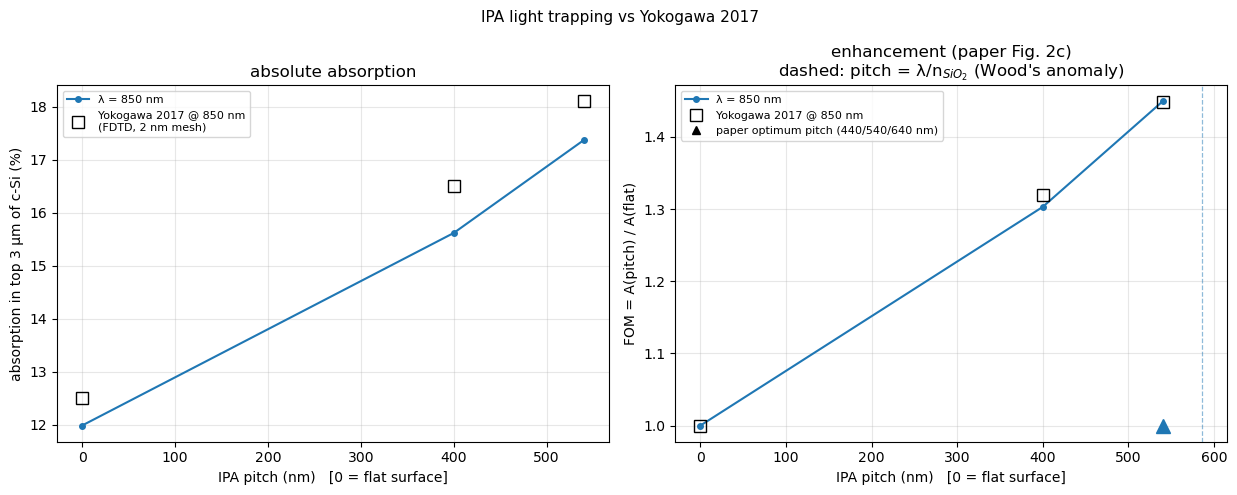

In [26]:
fig2, (axA, axF) = plt.subplots(1, 2, figsize=(12.5, 5))
for wavelength in WAVELENGTHS:
    rows = [r for r in results if r["wavelength"] == wavelength]
    x = [0 if r["pitch"] is None else r["pitch"] * 1e3 for r in rows]
    line, = axA.plot(x, [r["A"] * 100 for r in rows], "o-", ms=4,
                     label=f"λ = {wavelength*1e3:.0f} nm")
    axF.plot(x, [r["fom"] for r in rows], "o-", ms=4, color=line.get_color(),
             label=f"λ = {wavelength*1e3:.0f} nm")
    axF.axvline(wavelength / n_sio2 * 1e3, ls="--", lw=0.9,
                color=line.get_color(), alpha=0.5)
    opt = PAPER_OPT_PITCH.get(round(wavelength, 3))
    if opt is not None:   # paper's text-stated optimum pitch for this wavelength
        axF.plot(opt * 1e3, 1.0, marker="^", ms=10, ls="none",
                 color=line.get_color(), clip_on=False)
paper_x = [0 if p is None else p * 1e3 for p in PAPER_A_850]
axA.plot(paper_x, [v * 100 for v in PAPER_A_850.values()], "s", mfc="none",
         mec="k", ms=9, label="Yokogawa 2017 @ 850 nm\n(FDTD, 2 nm mesh)")
axF.plot(paper_x, [v / PAPER_A_850[None] for v in PAPER_A_850.values()], "s",
         mfc="none", mec="k", ms=9, label="Yokogawa 2017 @ 850 nm")
axF.plot([], [], marker="^", ls="none", color="k",
         label="paper optimum pitch (440/540/640 nm)")
axA.set_xlabel("IPA pitch (nm)   [0 = flat surface]")
axA.set_ylabel("absorption in top 3 μm of c-Si (%)")
axA.set_title("absolute absorption")
axF.set_xlabel("IPA pitch (nm)   [0 = flat surface]")
axF.set_ylabel("FOM = A(pitch) / A(flat)")
axF.set_title("enhancement (paper Fig. 2c)\n"
              "dashed: pitch = λ/n$_{SiO_2}$ (Wood's anomaly)")
for ax in (axA, axF):
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig2.suptitle("IPA light trapping vs Yokogawa 2017", fontsize=11)
fig2.tight_layout()
fig2.savefig(f"{OUTPUT_DIR}/mx_ipa_absorption.png", dpi=300, bbox_inches="tight")

**Paper Fig. 2, for comparison** (full caption at the top of the notebook). Panel (c) is the counterpart of the FOM plot above; its light dashed lines are the same λ/n_SiO₂ verticals.

![Paper Fig. 2](img/paper_fig2.jpg)

*Figure reproduced from Yokogawa et al., Sci. Rep. 7:3832 (2017), [doi:10.1038/s41598-017-04200-y](https://doi.org/10.1038/s41598-017-04200-y), under a [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) licence. Unmodified.*

### Save the table and show the figures

In [27]:
np.savetxt(f"{OUTPUT_DIR}/mx_ipa_absorption.csv",
           np.array([[r["wavelength"] * 1e3, 0 if r["pitch"] is None else r["pitch"] * 1e3,
                      r["A"], r["fom"]] for r in results]),
           delimiter=",", header="wavelength_nm,pitch_nm,absorbed_fraction,fom", comments="")

print(f"\nSaved output/{NAME}/mx_ipa_fields.png, mx_ipa_absorption.png and .csv")
plt.show()


Saved output/mx_ipa_light_trapping/mx_ipa_fields.png, mx_ipa_absorption.png and .csv
